=== 1. LINEARSVC WITH CLASS_WEIGHT='BALANCED' ===
              precision    recall  f1-score   support

           0       0.88      0.93      0.91      1409
           1       0.42      0.35      0.38       167
           2       0.93      0.90      0.92      1590

    accuracy                           0.89      3166
   macro avg       0.75      0.73      0.74      3166
weighted avg       0.88      0.89      0.88      3166



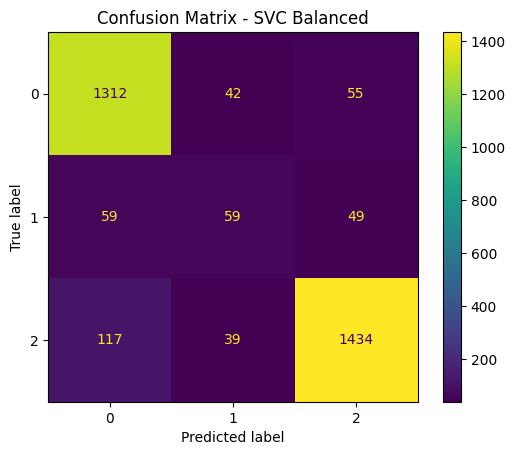

In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from imblearn.over_sampling import SMOTE, RandomOverSampler

train_df = pd.read_csv('../data/processed/train_cleaned.csv')
test_df = pd.read_csv('../data/raw/test.csv')
train_df.dropna(inplace=True)

tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)

def clean_text(text):
    text = str(text).lower() 
    text = re.sub(r'[^\w\s]','', text) 
    text = re.sub(r'\b\w*\d\w*\b', '', text)
    text = re.sub(r'\s+',' ', text).strip() 
    return text

X_train = tfidf.fit_transform(train_df['tokenized'])
y_train = train_df['label']
X_test = tfidf.transform(test_df['comment'].apply(clean_text))
y_test = test_df['label']

print("=== 1. LINEARSVC WITH CLASS_WEIGHT='BALANCED' ===")
svc_balanced = LinearSVC(class_weight='balanced', random_state=42)
svc_balanced.fit(X_train, y_train)

y_pred_svc = svc_balanced.predict(X_test)
print(classification_report(y_test, y_pred_svc))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_svc)
plt.title("Confusion Matrix - SVC Balanced")
plt.savefig('../results/Confusion_Matrix_SVC+balanced.png')
plt.show()



=== 2. PHƯƠNG THỨC OVERSAMPLING ===

Kết quả sau khi chạy RandomOverSampler:
              precision    recall  f1-score   support

           0       0.89      0.90      0.89      1409
           1       0.33      0.43      0.37       167
           2       0.94      0.89      0.91      1590

    accuracy                           0.87      3166
   macro avg       0.72      0.74      0.73      3166
weighted avg       0.88      0.87      0.88      3166



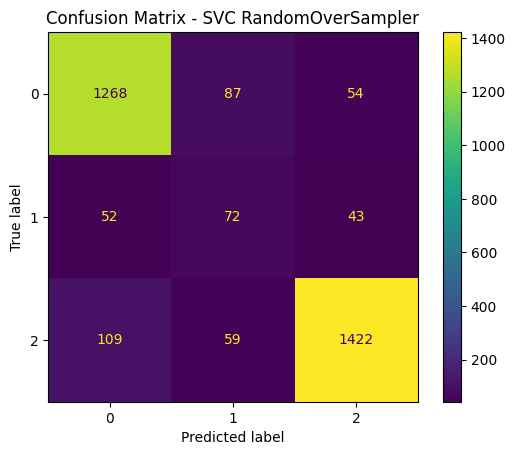


Kết quả sau khi chạy SMOTE:
              precision    recall  f1-score   support

           0       0.89      0.91      0.90      1409
           1       0.36      0.44      0.40       167
           2       0.94      0.89      0.92      1590

    accuracy                           0.88      3166
   macro avg       0.73      0.75      0.74      3166
weighted avg       0.89      0.88      0.88      3166



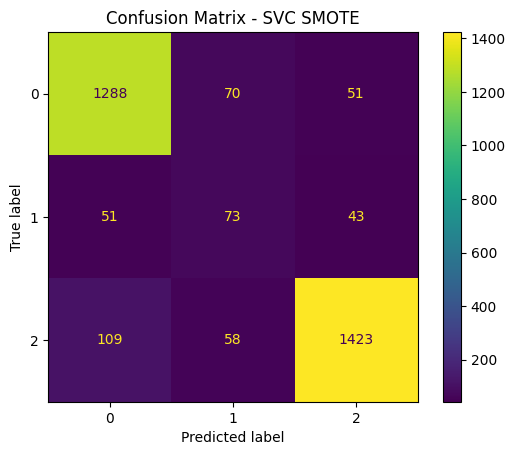

In [37]:

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from imblearn.over_sampling import SMOTE, RandomOverSampler

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^\w\s]', '', text)
    text = re.sub(r'\b\w*\d\w*\b', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

train_df = pd.read_csv('../data/processed/train_cleaned.csv')
test_df = pd.read_csv('../data/raw/test.csv')
train_df.dropna(inplace=True)

tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)
X_train = tfidf.fit_transform(train_df['tokenized'])
y_train = train_df['label']

X_test = tfidf.transform(test_df['comment'].apply(clean_text))
y_test = test_df['label']


print("=== 2. PHƯƠNG THỨC OVERSAMPLING ===")
ros = RandomOverSampler(random_state=42)
X_train_ros, y_train_ros = ros.fit_resample(X_train, y_train)
svc_ros = LinearSVC(random_state=42)
svc_ros.fit(X_train_ros, y_train_ros)
y_pred_ros = svc_ros.predict(X_test)
print("\nKết quả sau khi chạy RandomOverSampler:")
print(classification_report(y_test, y_pred_ros))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_ros)
plt.title("Confusion Matrix - SVC RandomOverSampler")
plt.savefig('../results/Confusion_Matrix_SVC_ROS.png')
plt.show()

smote = SMOTE(random_state=42)
X_train_smt, y_train_smt = smote.fit_resample(X_train, y_train)
svc_smt = LinearSVC(random_state=42)
svc_smt.fit(X_train_smt, y_train_smt)
y_pred_smt = svc_smt.predict(X_test)
print("\nKết quả sau khi chạy SMOTE:")
print(classification_report(y_test, y_pred_smt))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_smt)
plt.title("Confusion Matrix - SVC SMOTE")
plt.savefig('../results/Confusion_Matrix_SVC_SMOTE.png')
plt.show()

=== 3. LOGISTIC REGRESSION BASELINE ===
              precision    recall  f1-score   support

           0       0.87      0.89      0.88      1409
           1       0.28      0.50      0.36       167
           2       0.96      0.87      0.91      1590

    accuracy                           0.86      3166
   macro avg       0.70      0.75      0.72      3166
weighted avg       0.88      0.86      0.87      3166



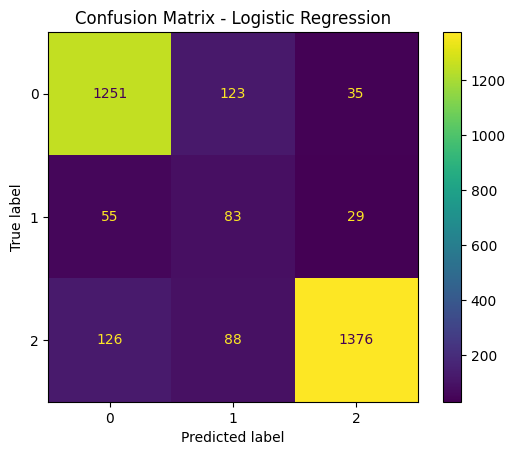

In [38]:

import pandas as pd
import numpy as np
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^\w\s]', '', text)
    text = re.sub(r'\b\w*\d\w*\b', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

train_df = pd.read_csv('../data/processed/train_cleaned.csv')
test_df = pd.read_csv('../data/raw/test.csv')
train_df.dropna(inplace=True)

tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)
X_train = tfidf.fit_transform(train_df['tokenized'])
y_train = train_df['label']

X_test = tfidf.transform(test_df['comment'].apply(clean_text))
y_test = test_df['label']

print("=== 3. LOGISTIC REGRESSION BASELINE ===")
log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)
y_pred_log = log_reg.predict(X_test)
print(classification_report(y_test, y_pred_log))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_log)
plt.title("Confusion Matrix - Logistic Regression")
plt.savefig('../results/Confusion_Matrix_Log_Reg.png')
plt.show()